# Image Branch — Integrity and Validity Audit

**Thesis:** Early detection of autism spectrum disorder in children aged 8 years or younger using multimodal machine learning
**Methodology:** CRISP-ML(Q) — *Data Understanding*, *Data Validation* and *Quality Assurance* phases

---

## Purpose

The questionnaire branch revealed that its target variable was a deterministic function of the predictors. Before training the image branch, we check whether it has an analogous problem.

Publicly available ASD facial datasets were built through internet searches, collecting photographs of children with ASD from association websites and groups, and controls from different sources. No subject has a confirmed diagnosis. When the classes come from different sources, a convolutional network can reach high accuracy by learning lighting, framing or composition, without processing any facial feature.

**This notebook does not train the final model.** It runs six tests that determine whether genuine facial signal exists, and that result decides the shape of Phase 2 (notebook 03).

## The six tests

| # | Test | What it detects |
|---|---|---|
| 1 | Duplication across splits | The same subject in train and test |
| 2 | Classifier without visual content | Bias in how the images were captured |
| 3 | Training without the face | Learning from context |
| 4 | Training on the face only | Signal in the facial region |
| 5 | Color ablation | Dependence on color and lighting |
| 6 | Alignment and geometry | Artificial framing versus morphology |

## Decision gate

| Result | Phase 2 |
|---|---|
| Clean audit | Standard model on the full image |
| Capture confounders | Model on the cropped, normalized face, with the artifact documented |
| No signal | The branch contributes $LR \approx 1$; it is reported as a negative result |

All three outcomes are publishable.

> **Repository `asd-screening-audit` · Notebook 2 of 5 — Image dataset audit**
>
> Academic research on early ASD screening with public data. **This is not a diagnostic tool** and its results must not be used for clinical decisions.

| | |
|---|---|
| **Run order** | Notebooks 01 → 02 → 03 → 04 → 05. Notebook 05 requires the outputs of 01, 03 and 04 (optional); 01 and 02 are independent of each other. |
| **Inputs** | `data/imagenes/` (folders `train`, `valid`, `test`, with one subfolder per class). Downloads the OpenCV YuNet detector from GitHub. |
| **Outputs** | In `outputs/rama_imagenes/`: manifest, `prueba1_duplicados.csv`, `cohorte_imagenes_deduplicada.csv`, tables of the six tests and `veredicto_auditoria_final.json`. |
| **Hardware** | GPU recommended (feature extraction) |
| **Data** | Source, license and folder layout: see `data/README.md` in the repository. |
| **Reproducibility** | Global seed `SEED = 42`. The first code cell defines `PROJECT_DIR`; there are no other hard-coded paths. |

> **Privacy.** Graphic outputs that show children's faces (example grids, crops, activation maps) were omitted from this repository. They are regenerated when the cells are run. All tables, metrics and aggregate plots are kept.

*File and folder names (`rama_imagenes`, `prueba1_...`) are kept in Spanish so that they match the original runs and the article.*

---
## 1. Environment Setup

Only `imagehash` is installed. **`mediapipe` is not installed**: it brings its own OpenCV version, installs it over the one in Colab and leaves both modules unusable until the session is restarted. Face detection is done with YuNet, which is included in OpenCV.

In [1]:
# ==============================================================================
# CELL 1: Dependencies and imports
# ==============================================================================
!pip install -q imagehash

import os, glob, json, hashlib, warnings, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
SEED = 42
np.random.seed(SEED)
print("Entorno configurado.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.1 MB/s eta 0:00:00
Entorno configurado.


### 1.1 Paths and structure discovery

The dataset has inconsistent naming: the positive class appears as `autism` in *Train* and *Test*, but as `autistic` in *valid*. An alias function is defined

$$\alpha: \mathcal{N} \rightarrow \{\text{autism},\ \text{typical}\}$$

which maps each observed name to a canonical class. Without it, a whole split would silently be loaded with the wrong label. The cell warns if it finds a folder name that is not covered.

In [2]:
# ==============================================================================
# CELL 2: Drive mounting and folder structure
# ==============================================================================
# Project paths. Only adjust PROJECT_DIR
# (outside Colab, set the environment variable ASD_PROJECT_DIR).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/asd-screening-audit"
except ImportError:
    PROJECT_DIR = os.environ.get("ASD_PROJECT_DIR", ".")

IMG_ROOT    = os.path.join(PROJECT_DIR, "data", "imagenes")
OUTPUTS_DIR = os.path.join(PROJECT_DIR, "outputs", "rama_imagenes")
os.makedirs(OUTPUTS_DIR, exist_ok=True)
assert os.path.isdir(IMG_ROOT), f"Path does not exist: {IMG_ROOT}"

ALIAS_CLASE = {'autism': 'autism', 'autistic': 'autism', 'asd': 'autism',
               'typical': 'typical', 'non_autistic': 'typical',
               'nonautistic': 'typical', 'normal': 'typical', 'control': 'typical'}
ALIAS_SPLIT = {'train': 'train', 'test': 'test', 'valid': 'valid',
               'validation': 'valid', 'val': 'valid'}
EXTENSIONES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

print("\nStructure found:\n")
for d_split in sorted(os.listdir(IMG_ROOT)):
    p_split = os.path.join(IMG_ROOT, d_split)
    if not os.path.isdir(p_split):
        continue
    subs = [d for d in sorted(os.listdir(p_split))
            if os.path.isdir(os.path.join(p_split, d))]
    print(f"  {d_split}/  ->  {subs}")
    for s in subs:
        if s.strip().lower() not in ALIAS_CLASE:
            print(f"     [!] '{s}' is not in ALIAS_CLASE. Add it before continuing.")

Mounted at /content/drive

Structure found:

  Test/  ->  ['autism', 'typical']
  Train/  ->  ['autism', 'typical']
  valid/  ->  ['autistic', 'typical']


### Environment versions

In [ ]:
# Environment versions (for the Methods section and requirements.txt)
import sys, platform, importlib.metadata as md
print("Python", sys.version.split()[0], "|", platform.platform())
for p in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "tensorflow", "keras",
          "opencv-python", "imagehash", "shap", "statsmodels", "matplotlib", "seaborn",
          "joblib", "Pillow"]:
    try: print(f"{p:<16}{md.version(p)}")
    except Exception: print(f"{p:<16}(not installed)")
try:
    import tensorflow as tf; print("GPU:", [d.name for d in tf.config.list_physical_devices('GPU')])
except Exception: pass


---
## 2. Phase 0 — Inventory

A manifest is built with one row per image. All later analysis operates on this table.

For each image, properties independent of the visual content are derived:

$$\text{aspect} = \frac{W}{H}, \qquad \text{pixels} = W \cdot H, \qquad \text{bpp} = \frac{\text{bytes}}{W \cdot H}$$

The **bytes per pixel** ratio indirectly estimates the JPEG compression level: the higher the encoding quality, the higher the $\text{bpp}$. It matters because images from different sources usually show different compression profiles.

In [3]:
# ==============================================================================
# CELL 3: Manifest construction
# ==============================================================================
registros = []
for d_split in sorted(os.listdir(IMG_ROOT)):
    p_split = os.path.join(IMG_ROOT, d_split)
    if not os.path.isdir(p_split):
        continue
    split = ALIAS_SPLIT.get(d_split.strip().lower(), d_split.strip().lower())
    for d_clase in sorted(os.listdir(p_split)):
        p_clase = os.path.join(p_split, d_clase)
        if not os.path.isdir(p_clase):
            continue
        clase = ALIAS_CLASE.get(d_clase.strip().lower())
        if clase is None:
            print(f"[!] Folder ignored: {d_split}/{d_clase}")
            continue
        for nombre in os.listdir(p_clase):
            if os.path.splitext(nombre)[1].lower() not in EXTENSIONES:
                continue
            ruta = os.path.join(p_clase, nombre)
            try:
                with Image.open(ruta) as im:
                    ancho, alto = im.size
                    modo, formato = im.mode, im.format
            except Exception as e:
                print(f"[!] Could not open {ruta}: {e}")
                continue
            registros.append({'ruta': ruta, 'archivo': nombre, 'split': split,
                              'clase': clase,
                              'carpeta_original': f"{d_split}/{d_clase}",
                              'ancho': ancho, 'alto': alto, 'modo': modo,
                              'formato': formato, 'bytes': os.path.getsize(ruta)})

mf = pd.DataFrame(registros)
mf['aspecto']  = mf['ancho'] / mf['alto']
mf['pixeles']  = mf['ancho'] * mf['alto']
mf['bytes_px'] = mf['bytes'] / mf['pixeles']
mf['target']   = (mf['clase'] == 'autism').astype(int)
mf = mf.reset_index(drop=True)

print(f"Total images indexed: {len(mf)}\n")
print(pd.crosstab(mf['split'], mf['clase'], margins=True))
print("\nFolder mapping applied:")
print(mf.groupby('carpeta_original')[['split', 'clase']].first().to_string())
mf.to_csv(os.path.join(OUTPUTS_DIR, "manifiesto_imagenes.csv"), index=False)

Total images indexed: 2801

clase  autism  typical   All
split                       
test      141      140   281
train    1210     1213  2423
valid      49       48    97
All      1400     1401  2801

Folder mapping applied:
                  split    clase
carpeta_original                
Test/autism        test   autism
Test/typical       test  typical
Train/autism      train   autism
Train/typical     train  typical
valid/autistic    valid   autism
valid/typical     valid  typical


### 2.1 Technical properties by class

First sign of capture bias. If the distributions of resolution, compression or color separate between classes, the images come from different sources or processes, and that difference is information a convolutional network can exploit with no relation to the face.

 TECHNICAL PROPERTIES BY CLASS
            n  ancho_medio  alto_medio  px_mediana  aspecto_medio  kb_medio  bytes_px
clase                                                                                
autism   1400        224.0       224.0     50176.0            1.0    18.016     0.368
typical  1401        224.0       224.0     50176.0            1.0    17.328     0.354

Formats by class:
formato  JPEG
clase        
autism   1400
typical  1401

Color modes by class:
modo      RGB
clase        
autism   1400
typical  1401


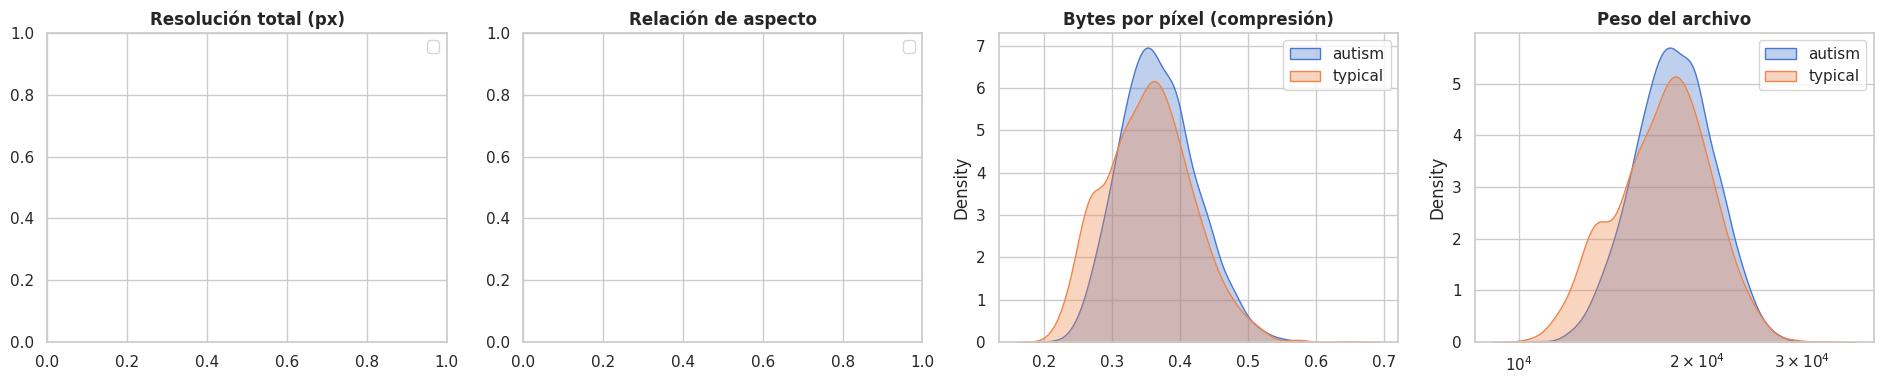

In [4]:
# ==============================================================================
# CELL 4: Technical properties by class
# ==============================================================================
print("=" * 80)
print(" TECHNICAL PROPERTIES BY CLASS")
print("=" * 80)
print(mf.groupby('clase').agg(
    n=('ruta', 'size'), ancho_medio=('ancho', 'mean'), alto_medio=('alto', 'mean'),
    px_mediana=('pixeles', 'median'), aspecto_medio=('aspecto', 'mean'),
    kb_medio=('bytes', lambda s: s.mean() / 1024), bytes_px=('bytes_px', 'mean'),
).round(3).to_string())

print("\nFormats by class:");      print(pd.crosstab(mf['clase'], mf['formato']))
print("\nColor modes by class:"); print(pd.crosstab(mf['clase'], mf['modo']))

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col, tit in zip(axes, ['pixeles', 'aspecto', 'bytes_px', 'bytes'],
        ['Total resolution (px)', 'Aspect ratio',
         'Bytes per pixel (compression)', 'File size']):
    for cl, sub in mf.groupby('clase'):
        if sub[col].nunique() > 1:
            sns.kdeplot(sub[col], ax=ax, label=cl, fill=True, alpha=0.35,
                        log_scale=(col in ['pixeles', 'bytes']))
    ax.set_title(tit, fontweight='bold'); ax.set_xlabel(''); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fase0_propiedades_tecnicas.png"), dpi=300)
plt.show()

### 2.2 Visual inspection

Direct inspection is valid methodological evidence and must be reported. When reviewing the sample it is worth asking:

- Do the backgrounds differ systematically between classes?
- Does one class concentrate studio photographs and the other spontaneous shots?
- Are there watermarks, borders or crops characteristic of one class?
- Are the distributions of apparent age and ethnic phenotype comparable?

In [5]:
# ==============================================================================
# CELL 5: Visual sample of both classes
# ==============================================================================
fig, axes = plt.subplots(2, 8, figsize=(19, 5.2))
for fila, cl in enumerate(['autism', 'typical']):
    sub = mf[mf.clase == cl].sample(min(8, (mf.clase == cl).sum()), random_state=SEED)
    for col, (_, r) in enumerate(sub.iterrows()):
        try:
            axes[fila, col].imshow(Image.open(r['ruta']).convert('RGB'))
        except Exception:
            pass
        axes[fila, col].axis('off')
        axes[fila, col].set_title(f"{r['ancho']}x{r['alto']}", fontsize=8)
plt.suptitle("Random sample — top: autism | bottom: typical", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fase0_muestra_visual.png"), dpi=300)
plt.show()

[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]


---
## 3. Test 1 — Duplication across splits

A duplicate between train and test means the model memorizes instead of generalizing, and the reported accuracy stops measuring predictive ability. It is the most frequent defect in datasets built by automated collection.

### 3.1 Perceptual difference hash (dHash)

A cryptographic hash such as MD5 only detects byte-for-byte identical files: a rescaled or recompressed image produces a completely different MD5 even though it is visually the same. A perceptual hash is therefore used.

Let $G \in \mathbb{R}^{s \times (s+1)}$ be the resized grayscale image, with $s = 8$. The dHash code is

$$h_{ij} = \mathbb{1}\left[G_{i,\,j+1} > G_{i,\,j}\right], \qquad i = 1..s,\ \ j = 1..s$$

which produces $s^2 = 64$ bits. It is invariant to scale and global brightness changes, because it encodes the **sign of the horizontal gradient** and not absolute values.

### 3.2 Hamming distance

$$d_H\big(h^{(a)}, h^{(b)}\big) = \sum_{k=1}^{64} \mathbb{1}\left[h^{(a)}_k \neq h^{(b)}_k\right]$$

Pairs with $d_H \leq \tau$ are considered near-duplicates.

> **Choice of $\tau$.** With $\tau = 5$ over 64 bits the criterion turned out too permissive for already cropped and centered faces, which share global structure. The visual check in Cell 8 allows adjusting it. For faces, $\tau \leq 3$ is recommended.

The cell includes its own NumPy dHash as a fallback, because `imagehash.phash` depends on SciPy for the discrete cosine transform and may fail depending on the installed version.

In [6]:
# ==============================================================================
# CELL 6: Test 1 — duplicate detection
# ==============================================================================
print("=" * 78)
print(" TEST 1 — DUPLICATES ACROSS SPLITS")
print("=" * 78)

# --- Check that imagehash works, and with which algorithm ---
ALGO, _errores_hash = None, []
try:
    import imagehash
    _prueba = Image.new('RGB', (64, 64), (128, 64, 32))
    for nombre, fn in [('phash', imagehash.phash),
                       ('dhash', imagehash.dhash),
                       ('average_hash', imagehash.average_hash)]:
        try:
            fn(_prueba, hash_size=8)
            ALGO = (nombre, fn)
            break
        except Exception as e:
            _errores_hash.append(f"{nombre}: {type(e).__name__}: {e}")
except Exception as e:
    _errores_hash.append(f"import imagehash: {type(e).__name__}: {e}")

if ALGO is None:
    print("  imagehash not operational. Errors:")
    for e in _errores_hash:
        print(f"    {e}")
    print("\n  Using own perceptual hash (numpy only, no dependencies).")

    def _hash_propio(im, lado=8):
        """dHash: compares each pixel with its right neighbor. Robust to
        rescaling and recompression, needs no scipy."""
        g = np.asarray(im.convert('L').resize((lado + 1, lado), Image.BILINEAR),
                       dtype=np.int16)
        return (g[:, 1:] > g[:, :-1]).flatten()
    calcular_hash = _hash_propio
    ALGO_NOMBRE = 'dhash_numpy'
else:
    ALGO_NOMBRE, _fn = ALGO
    print(f"  imagehash operational. Algorithm: {ALGO_NOMBRE}")

    def calcular_hash(im, lado=8):
        return np.asarray(_fn(im, hash_size=lado).hash).flatten()
    calcular_hash = calcular_hash

# --- Compute hashes, counting real failures ---
print("\n  Calculando hashes...")
bits, md5s, idx_ok, fallos = [], [], [], []
for i, r in mf.iterrows():
    try:
        with Image.open(r['ruta']) as im:
            im = im.convert('RGB')
            bits.append(calcular_hash(im))
        with open(r['ruta'], 'rb') as f:
            md5s.append(hashlib.md5(f.read()).hexdigest())
        idx_ok.append(i)
    except Exception as e:
        fallos.append(f"{os.path.basename(r['ruta'])}: {type(e).__name__}: {e}")

print(f"  Hashes computed    : {len(bits)} de {len(mf)}")
print(f"  Failures          : {len(fallos)}")
if fallos:
    print("  First errors:")
    for e in fallos[:5]:
        print(f"    {e}")

if len(bits) == 0:
    raise RuntimeError("No hash could be computed. Check the errors above.")

base_h = mf.iloc[idx_ok].reset_index(drop=True)
base_h['md5'] = md5s
H = np.array(bits, dtype=bool)

# --- Byte-for-byte duplicates ---
dup_md5 = base_h[base_h.duplicated('md5', keep=False)]
print(f"\n  [A] Byte-identical files: {len(dup_md5)}")
if len(dup_md5):
    print(dup_md5.groupby('md5').agg(
        n=('ruta', 'size'),
        splits=('split', lambda s: sorted(set(s))),
        clases=('clase', lambda s: sorted(set(s)))).head(12).to_string())

# --- Perceptual duplicates by blocks ---
UMBRAL = 5
print(f"\n  [B] Pairs with Hamming distance <= {UMBRAL}...")
pares, BLOQUE = [], 400
for i0 in range(0, len(H), BLOQUE):
    blq = H[i0:i0 + BLOQUE]
    d = (blq[:, None, :] != H[None, :, :]).sum(axis=2)
    for li, gi in zip(*np.where(d <= UMBRAL)):
        i = i0 + li
        if i < gi:
            pares.append((i, int(gi), int(d[li, gi])))
print(f"      Pairs found: {len(pares)}")

if pares:
    dp = pd.DataFrame([{
        'archivo_a': base_h.archivo[i], 'split_a': base_h.split[i], 'clase_a': base_h.clase[i],
        'archivo_b': base_h.archivo[j], 'split_b': base_h.split[j], 'clase_b': base_h.clase[j],
        'hamming': d} for i, j, d in pares])
    dp['cruza_split'] = dp.split_a != dp.split_b
    dp['cruza_clase'] = dp.clase_a != dp.clase_b
    dp.to_csv(os.path.join(OUTPUTS_DIR, "prueba1_duplicados.csv"), index=False)
    n_cross, n_clase = int(dp.cruza_split.sum()), int(dp.cruza_clase.sum())
    print(f"      Cruzan particiones : {n_cross}   <-- CRITICAL if > 0")
    print(f"      Clases distintas   : {n_clase}   <-- contradictory labels")
    if n_cross:
        print("\n      Examples:")
        print(dp[dp.cruza_split].head(8).to_string(index=False))
else:
    n_cross = n_clase = 0

print("\n" + "-" * 78)
if n_cross == 0 and len(dup_md5) == 0:
    P1 = "LIMPIA"
    print(f" No duplication across splits ({ALGO_NOMBRE}, n={len(H)}). Split usable.")
else:
    P1 = "FALLA"
    print(f" FUGA: {n_cross} pairs cross splits, {len(dup_md5)} identical files.")
    print(" Deduplicate and re-split before training.")
print("-" * 78)

 TEST 1 — DUPLICATES ACROSS SPLITS
  imagehash operational. Algorithm: phash

  Calculando hashes...
  Hashes computed    : 2801 de 2801
  Failures          : 0

  [A] Byte-identical files: 0

  [B] Pairs with Hamming distance <= 5...
      Pairs found: 8
      Cruzan particiones : 3   <-- CRITICAL if > 0
      Clases distintas   : 0   <-- contradictory labels

      Examples:
archivo_a split_a clase_a archivo_b split_b clase_b  hamming  cruza_split  cruza_clase
  094.jpg    test  autism  0874.jpg   train  autism        4         True        False
  067.jpg    test typical  0829.jpg   train typical        2         True        False
 0762.jpg   train  autism    32.jpg   valid  autism        2         True        False

------------------------------------------------------------------------------
 FUGA: 3 pairs cross splits, 0 identical files.
 Deduplicate and re-split before training.
------------------------------------------------------------------------------


---
## 4. Test 2 — Classifier without visual content

We train a classifier that **never sees the image**: it receives only file properties and global color statistics.

### 4.1 Feature vector

Each image is reduced to $32 \times 32$ and summarized in $\mathbf{m}_i \in \mathbb{R}^{15}$:

**From the file:** $W$, $H$, aspect, pixels, bytes, bpp.

**Per channel**, with $c \in \{R,G,B\}$:

$$\mu_c = \frac{1}{HW}\sum_{u,v} x_{uvc}, \qquad \sigma_c = \sqrt{\frac{1}{HW}\sum_{u,v}\left(x_{uvc} - \mu_c\right)^2}$$

**Luminance** (ITU-R BT.601), from which brightness $=\bar{Y}$ and contrast $=\sigma_Y$ are obtained:

$$Y_{uv} = 0.299\,R_{uv} + 0.587\,G_{uv} + 0.114\,B_{uv}$$

**Mean saturation:**

$$S = \frac{1}{HW}\sum_{u,v}\left(\max_c x_{uvc} - \min_c x_{uvc}\right)$$

### 4.2 Rationale

$\mathbf{m}_i$ contains no information about the shape of the face. If a classifier on $\mathbf{m}$ consistently beats chance, there is a systematic difference in how the images of each class were captured — and any convolutional network trained on those same images will have access to it.

A random forest of 400 trees with maximum depth 8 is used, validated with stratified $k$-fold, $k = 10$.

 PRIOR CHECK
  mf (full manifest)       : 2801 filas
  base_h (after hashing)  : 2801 filas
  Class distribution       : {0: np.int64(1401), 1: np.int64(1400)}

Extracting color and file statistics...
  Processed successfully  : 2801
  Fallidas                 : 0

Metadata matrix: (2801, 15)
Clases: {0: np.int64(1401), 1: np.int64(1400)}

 TEST 2 VERDICT — classifier WITHOUT visual content (10 folds)
 ROC-AUC  : 0.7357 ± 0.0316
 Accuracy : 66.83% ± 2.96%
 Majority class (reference): 50.02%

 Moderate capture bias. Document as a limitation.


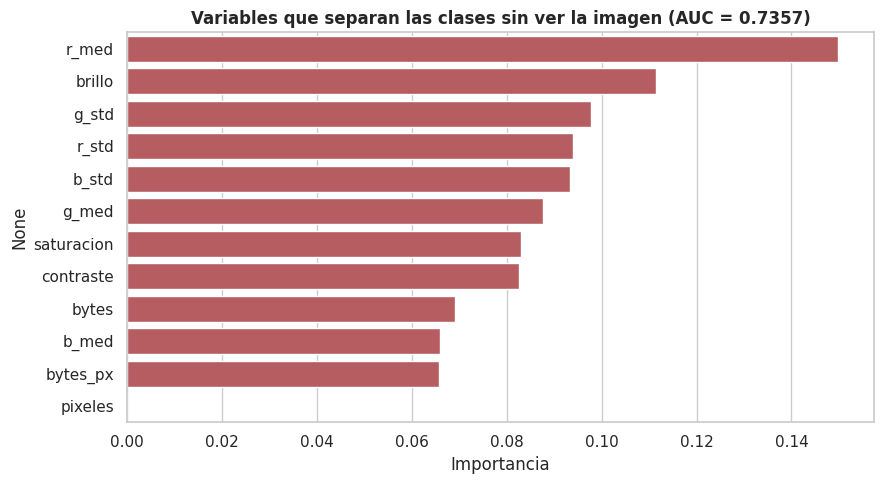

In [7]:
# ==============================================================================
# CELL 7: Test 2 — classifier without visual content
# ==============================================================================
print("=" * 72)
print(" PRIOR CHECK")
print("=" * 72)

if 'mf' not in dir() or len(mf) == 0:
    raise RuntimeError("'mf' is empty or does not exist. Run cell 3 again.")
print(f"  mf (full manifest)       : {len(mf)} filas")

# This cell does NOT depend on cell 6. If 'mf_ok' exists and has data it uses it;
# otherwise, it works directly on 'mf'.
base = base_h.reset_index(drop=True)
print(f"  base_h (after hashing)  : {len(base)} filas")

if 'target' not in base.columns:
    raise RuntimeError(f"Column 'target' is missing. Columns: {list(base.columns)}")
print(f"  Class distribution       : {dict(base['target'].value_counts())}")
print("=" * 72)


# ------------------------------------------------------------------------------
# 7.1 — Metadata extraction, recording failures
# ------------------------------------------------------------------------------
print("\nExtracting color and file statistics...")
filas_meta, errores = [], []

for i, r in base.iterrows():
    try:
        with Image.open(r['ruta']) as im:
            a = np.asarray(im.convert('RGB').resize((32, 32)),
                           dtype=np.float32) / 255.0
    except Exception as e:
        errores.append({'ruta': r['ruta'], 'error': f"{type(e).__name__}: {e}"})
        continue

    if a.ndim != 3 or a.shape[2] != 3:
        errores.append({'ruta': r['ruta'], 'error': f"unexpected shape {a.shape}"})
        continue

    gris = a.mean(axis=2)
    filas_meta.append({
        'ancho': r['ancho'], 'alto': r['alto'], 'aspecto': r['aspecto'],
        'pixeles': r['pixeles'], 'bytes': r['bytes'], 'bytes_px': r['bytes_px'],
        'r_med': a[:, :, 0].mean(), 'g_med': a[:, :, 1].mean(), 'b_med': a[:, :, 2].mean(),
        'r_std': a[:, :, 0].std(),  'g_std': a[:, :, 1].std(),  'b_std': a[:, :, 2].std(),
        'brillo': gris.mean(), 'contraste': gris.std(),
        'saturacion': (a.max(axis=2) - a.min(axis=2)).mean(),
        'target': r['target'],
    })

print(f"  Processed successfully  : {len(filas_meta)}")
print(f"  Fallidas                 : {len(errores)}")

if errores:
    print("\n  First errors found:")
    for e in errores[:5]:
        print(f"    {os.path.basename(e['ruta'])}: {e['error']}")
    tipos = pd.Series([e['error'].split(':')[0] for e in errores]).value_counts()
    print(f"\n  Error types: {dict(tipos)}")

if len(filas_meta) == 0:
    raise RuntimeError(
        "No image could be processed.\n"
        "Causas frecuentes:\n"
        "  - Drive was unmounted: run cell 2 again.\n"
        "  - The manifest paths are no longer valid: re-run cell 3.\n"
        "  - Corrupt files or unsupported format (see errors above)."
    )

dm = pd.DataFrame(filas_meta)
X_meta, y_meta = dm.drop(columns='target'), dm['target']
print(f"\nMetadata matrix: {X_meta.shape}")
print(f"Clases: {dict(y_meta.value_counts())}")

if y_meta.nunique() < 2:
    raise RuntimeError("Only one class remained. Check the ALIAS_CLASE mapping (cell 2).")


# ------------------------------------------------------------------------------
# 7.2 — Training the classifier without visual content
# ------------------------------------------------------------------------------
n_folds = min(10, int(y_meta.value_counts().min()))
cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
clf_meta = Pipeline([('scl', StandardScaler()),
                     ('rf', RandomForestClassifier(n_estimators=400, max_depth=8,
                                                   random_state=SEED, n_jobs=-1))])
auc_meta = cross_val_score(clf_meta, X_meta, y_meta, cv=cv, scoring='roc_auc')
acc_meta = cross_val_score(clf_meta, X_meta, y_meta, cv=cv, scoring='accuracy')
AUC_META = float(auc_meta.mean())

print("\n" + "=" * 72)
print(f" TEST 2 VERDICT — classifier WITHOUT visual content ({n_folds} folds)")
print("=" * 72)
print(f" ROC-AUC  : {AUC_META:.4f} ± {auc_meta.std():.4f}")
print(f" Accuracy : {acc_meta.mean()*100:.2f}% ± {acc_meta.std()*100:.2f}%")
print(f" Majority class (reference): {max(y_meta.mean(), 1-y_meta.mean())*100:.2f}%")
if AUC_META < 0.60:
    P2 = "LIMPIA";   print("\n No relevant capture bias.")
elif AUC_META < 0.75:
    P2 = "MODERADA"; print("\n Moderate capture bias. Document as a limitation.")
else:
    P2 = "FALLA"
    print("\n SEVERE BIAS: the classes are separable without looking at the image.")
    print(" Any CNN metric on these images is contaminated.")
print("=" * 72)

clf_meta.fit(X_meta, y_meta)
imp = pd.Series(clf_meta.named_steps['rf'].feature_importances_,
                index=X_meta.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=imp.values[:12], y=imp.index[:12], color='#C44E52')
plt.title(f"Variables that separate the classes without seeing the image (AUC = {AUC_META:.4f})",
          fontweight='bold')
plt.xlabel("Importancia")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "prueba2_metadatos.png"), dpi=300)
plt.show()

---
## 5. Tests 3 and 4 — Face versus context

The face is detected and two complementary variants are generated:

- **Face only:** crop of the facial region. If the model works here, there is an indication of facial signal.
- **No face:** the facial region is occluded in black. If the model works here, it is learning from context.

### 5.1 Detection and bounding box

**YuNet** is used, a lightweight convolutional detector included in OpenCV, which returns the box $(x, y, w, h)$ and five facial landmarks. It requires no additional installation.

A relative margin of 15 % is applied to include the periocular region, which is relevant in the facial phenotype literature:

$$
\begin{aligned}
x_0 &= \max(0,\ x - 0.15\,w), & x_1 &= \min(W,\ x + w + 0.15\,w)\\
y_0 &= \max(0,\ y - 0.15\,h), & y_1 &= \min(H,\ y + h + 0.15\,h)
\end{aligned}
$$

### 5.2 Variants

$$x^{\text{face}} = \mathcal{R}\big(x[y_0{:}y_1,\ x_0{:}x_1]\big), \qquad
x^{\text{background}}_{uv} = \begin{cases} \mathbf{0} & (u,v) \in [y_0,y_1]\times[x_0,x_1] \\[2pt] x_{uv} & \text{otherwise}\end{cases}$$

with $\mathcal{R}$ the bilinear resize to $224 \times 224$.

> **Note.** Since the images already come cropped to the face, the box covers most of the canvas and $x^{\text{background}}$ ends up almost entirely black. That it still classifies above chance reinforces the conclusion about low-level confounders.

### 5.3 Additional diagnostic: detection gap

The cell reports the detection rate per class. A difference greater than 15 points indicates that the photographs of one class have systematically different framing, sharpness or pose, and constitutes a finding independent of Test 2.

In [8]:
# ==============================================================================
# CELL 8: Face detection (YuNet) and variant generation
# ==============================================================================
import os
import numpy as np
from PIL import Image

TAM = 224

# ------------------------------------------------------------------------------
# 8.0 — Diagnostics
# ------------------------------------------------------------------------------
print("=" * 74)
print(" LIBRARY DIAGNOSTICS")
print("=" * 74)
try:
    import cv2
    print(f"  cv2 version     : {getattr(cv2, '__version__', '?')}")
    print(f"  FaceDetectorYN  : {hasattr(cv2, 'FaceDetectorYN')}")
    print(f"  CascadeClassifier: {hasattr(cv2, 'CascadeClassifier')}")
except Exception as e:
    cv2 = None
    print(f"  cv2 no importable: {type(e).__name__}")
print("=" * 74)


def redimensionar(arr, tam=TAM):
    """Resizes an RGB array using PIL (independent of the cv2 version)."""
    if arr is None or arr.size == 0:
        return np.zeros((tam, tam, 3), np.uint8)
    return np.asarray(Image.fromarray(arr.astype(np.uint8))
                      .resize((tam, tam), Image.BILINEAR))


# ------------------------------------------------------------------------------
# 8.1 — Detector selection
# ------------------------------------------------------------------------------
BACKEND, _yunet, _mtcnn, _cascadas = None, None, None, []

# --- Option 1: YuNet (included in OpenCV >= 4.5.4 and in OpenCV 5) ---
if cv2 is not None and hasattr(cv2, 'FaceDetectorYN'):
    try:
        import urllib.request
        MODELO = '/content/face_detection_yunet_2023mar.onnx'
        # The opencv_zoo repo stores the models in Git LFS: the normal 'raw' URL
        # returns a ~130-byte text pointer, not the ONNX. The LFS media URL must be used
        # and the size of the downloaded file validated.
        URLS = [
            'https://media.githubusercontent.com/media/opencv/opencv_zoo/main/'
            'models/face_detection_yunet/face_detection_yunet_2023mar.onnx',
            'https://github.com/opencv/opencv_zoo/raw/main/models/'
            'face_detection_yunet/face_detection_yunet_2023mar.onnx',
        ]
        if not (os.path.exists(MODELO) and os.path.getsize(MODELO) > 100_000):
            for u in URLS:
                try:
                    print(f"  Downloading YuNet from {u.split('/')[2]} ...")
                    urllib.request.urlretrieve(u, MODELO)
                    tam = os.path.getsize(MODELO)
                    if tam > 100_000:
                        print(f"  Model downloaded: {tam:,} bytes")
                        break
                    print(f"  [!] Only {tam} bytes (LFS pointer). Trying another URL.")
                    os.remove(MODELO)
                except Exception as e:
                    print(f"  [!] Failed: {type(e).__name__}")
        if not (os.path.exists(MODELO) and os.path.getsize(MODELO) > 100_000):
            raise RuntimeError("could not download the YuNet model")
        _yunet = cv2.FaceDetectorYN.create(MODELO, "", (320, 320),
                                           score_threshold=0.5, nms_threshold=0.3)
        BACKEND = 'yunet'
        print(">>> Detector: YuNet (OpenCV DNN)")
    except Exception as e:
        print(f"  YuNet no disponible: {type(e).__name__}: {e}")

# --- Option 2: MTCNN ---
if BACKEND is None:
    try:
        import torch
        from facenet_pytorch import MTCNN
        _dev = 'cuda' if torch.cuda.is_available() else 'cpu'
        _mtcnn = MTCNN(keep_all=True, select_largest=True, post_process=False,
                       min_face_size=20, device=_dev)
        BACKEND = 'mtcnn'
        print(f">>> Detector: MTCNN en {_dev}")
    except Exception as e:
        print(f"  MTCNN no disponible: {type(e).__name__}")

# --- Option 3: Haar (OpenCV 4.x only) ---
if cv2 is not None and hasattr(cv2, 'CascadeClassifier'):
    for f in ['haarcascade_frontalface_default.xml',
              'haarcascade_frontalface_alt2.xml']:
        try:
            c = cv2.CascadeClassifier(cv2.data.haarcascades + f)
            if not c.empty():
                _cascadas.append(c)
        except Exception:
            pass
    if BACKEND is None and _cascadas:
        BACKEND = 'haar'
        print(f">>> Detector: cascadas de Haar ({len(_cascadas)})")

if BACKEND is None:
    raise RuntimeError(
        "No detector available.\n"
        "Run in a new cell (without -q, to see errors):\n"
        "    !pip install facenet-pytorch\n"
        "Then: Runtime -> Restart session, and run from cell 1."
    )


# ------------------------------------------------------------------------------
# 8.2 — Unified detection function
# ------------------------------------------------------------------------------
def detectar_rostro(img_rgb):
    """Returns (x, y, w, h) of the largest face, or None."""
    h, w = img_rgb.shape[:2]

    if BACKEND == 'yunet':
        try:
            _yunet.setInputSize((w, h))
            bgr = np.ascontiguousarray(img_rgb[:, :, ::-1])   # YuNet expects BGR
            _, caras = _yunet.detect(bgr)
            if caras is not None and len(caras):
                x, y, bw, bh = max(caras, key=lambda f: f[2] * f[3])[:4]
                x, y = max(0, int(x)), max(0, int(y))
                bw, bh = int(bw), int(bh)
                if bw > 10 and bh > 10:
                    return x, y, min(bw, w - x), min(bh, h - y)
        except Exception:
            pass

    elif BACKEND == 'mtcnn':
        try:
            cajas, _ = _mtcnn.detect(Image.fromarray(img_rgb))
            if cajas is not None and len(cajas):
                x1, y1, x2, y2 = max(cajas, key=lambda b: (b[2]-b[0]) * (b[3]-b[1]))
                x, y = max(0, int(x1)), max(0, int(y1))
                bw, bh = int(x2) - x, int(y2) - y
                if bw > 10 and bh > 10:
                    return x, y, min(bw, w - x), min(bh, h - y)
        except Exception:
            pass

    if _cascadas:
        gris = np.asarray(Image.fromarray(img_rgb).convert('L'))
        cand = []
        for casc in _cascadas:
            try:
                cand.extend(casc.detectMultiScale(gris, 1.08, 4, minSize=(24, 24)))
            except Exception:
                continue
        if len(cand):
            x, y, bw, bh = max(cand, key=lambda c: c[2] * c[3])
            return int(x), int(y), int(bw), int(bh)
    return None


# ------------------------------------------------------------------------------
# 8.3 — Generation of the three variants
# ------------------------------------------------------------------------------
print("\nProcessing images and generating variants...")
completas, solo_rostro, sin_rostro = [], [], []
etiquetas, splits, detectado, fallos = [], [], [], []

for k, (_, r) in enumerate(base_h.iterrows()):
    if k % 300 == 0:
        print(f"   {k}/{len(base_h)}")
    try:
        img = np.asarray(Image.open(r['ruta']).convert('RGB'))
    except Exception as e:
        fallos.append(f"{os.path.basename(r['ruta'])}: {type(e).__name__}")
        continue

    caja = detectar_rostro(img)
    detectado.append(caja is not None)
    completas.append(redimensionar(img))

    if caja is not None:
        x, y, bw, bh = caja
        mx, my = int(bw * 0.15), int(bh * 0.15)
        x0, y0 = max(0, x - mx), max(0, y - my)
        x1 = min(img.shape[1], x + bw + mx)
        y1 = min(img.shape[0], y + bh + my)
        solo_rostro.append(redimensionar(img[y0:y1, x0:x1]))
        ocluida = img.copy()
        ocluida[y0:y1, x0:x1] = 0
        sin_rostro.append(redimensionar(ocluida))
    else:
        solo_rostro.append(np.zeros((TAM, TAM, 3), np.uint8))
        sin_rostro.append(redimensionar(img))

    etiquetas.append(r['target'])
    splits.append(r['split'])

if fallos:
    print(f"\n[!] {len(fallos)} images could not be opened. Examples: {fallos[:3]}")

completas   = np.array(completas,   dtype=np.uint8)
solo_rostro = np.array(solo_rostro, dtype=np.uint8)
sin_rostro  = np.array(sin_rostro,  dtype=np.uint8)
y_img = np.array(etiquetas)
det   = np.array(detectado)

print(f"\nImages processed : {len(y_img)}")
print(f"Face detected     : {det.sum()} ({det.mean()*100:.1f}%)  [backend: {BACKEND}]")
if det.mean() < 0.50:
    print("\n[!] Low detection rate: tests 3 and 4 will use few images.")
    print("    Report it as a limitation of the study.")

print("\nDetection rate by class:")
print(pd.crosstab(pd.Series(y_img).map({0: 'typical', 1: 'autism'}),
                  pd.Series(det).map({True: 'detectado', False: 'not detected'}),
                  normalize='index').round(3))

_t_aut = det[y_img == 1].mean() if (y_img == 1).any() else np.nan
_t_typ = det[y_img == 0].mean() if (y_img == 0).any() else np.nan
print(f"\nDetection gap autism vs typical: {abs(_t_aut - _t_typ)*100:.1f} puntos")
if abs(_t_aut - _t_typ) > 0.15:
    print("  >> Gap greater than 15 points: the photos of one class have systematically")
    print("     different framing, sharpness or pose. It is capture bias, and")
    print("     constitutes a finding independent of Test 2.")

# ------------------------------------------------------------------------------
# 8.4 — Comparative view
# ------------------------------------------------------------------------------
idx_ej = np.where(det)[0][:4]
if len(idx_ej):
    fig, axes = plt.subplots(3, len(idx_ej), figsize=(3 * len(idx_ej), 9))
    axes = np.atleast_2d(axes).reshape(3, -1)
    for c, i in enumerate(idx_ej):
        for f, (arr, tit) in enumerate([(completas, 'Full'),
                                        (solo_rostro, 'Face only'),
                                        (sin_rostro, 'No face')]):
            axes[f, c].imshow(arr[i]); axes[f, c].axis('off')
            if c == 0:
                axes[f, c].set_title(tit, loc='left', fontweight='bold')
    plt.suptitle(f"The three input variants (detector: {BACKEND})",
                 fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUTS_DIR, "pruebas34_variantes.png"), dpi=300)
    plt.show()
else:
    print("\n[!] No face detected. Check the diagnostics of section 8.0.")

 LIBRARY DIAGNOSTICS
  cv2 version     : 5.0.0
  FaceDetectorYN  : True
  CascadeClassifier: False
  Model downloaded: 232,589 bytes
>>> Detector: YuNet (OpenCV DNN)

Processing images and generating variants...
   0/2801
   300/2801
   600/2801
   900/2801
   1200/2801
   1500/2801
   1800/2801
   2100/2801
   2400/2801
   2700/2801

Images processed : 2801
Face detected     : 2801 (100.0%)  [backend: yunet]

Detection rate by class:
col_0    detectado
row_0             
autism         1.0
typical        1.0

Detection gap autism vs typical: 0.0 puntos


[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]


### 5.4 Feature extraction and classification

**Frozen extractor.** EfficientNetV2B0 pretrained on ImageNet, without classification layer and with global average pooling:

$$\mathbf{z}_i = f_\theta(x_i) \in \mathbb{R}^{1280}, \qquad \theta \text{ fixed}$$

Freezing $\theta$ is deliberate: the goal is not to maximize performance but to **compare variants under equal conditions**. Fine-tuning would introduce additional variation between variants and confound the comparison.

**Classifier.** Logistic regression with $\ell_2$ penalty on the standardized *embeddings*:

$$\min_{\mathbf{w},\,b}\ \ \frac{1}{2}\|\mathbf{w}\|_2^2 + C\sum_{i=1}^{n}\log\!\left(1 + e^{-\tilde{y}_i\left(\mathbf{w}^\top \mathbf{z}_i + b\right)}\right), \qquad \tilde{y}_i \in \{-1,+1\}$$

With $C = 0.1$. Since $C$ multiplies the loss term, a low value implies strong regularization, appropriate given that $d = 1280$ far exceeds the size of each fold.

**Metric.** Area under the ROC curve:

$$\text{AUC} = \mathbb{P}\big(s(x^+) > s(x^-)\big) = \frac{1}{n_+ n_-}\sum_{i:\,y_i=1}\ \sum_{j:\,y_j=0} \mathbb{1}\left[s_i > s_j\right]$$

It is preferred over accuracy because it does not depend on the decision threshold, which allows comparing variants without fixing an operating point.

GPU disponible: True
24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
   Extrayendo: Full image ...
   Extrayendo: Face only ...
   Extrayendo: No face ...

 TABLE — TESTS 3 AND 4 (frozen EfficientNetV2B0 + logistic, 10-fold CV)
       Variant    n         ROC-AUC Accuracy (%)
Full image 2801 0.8651 ± 0.0221 78.22 ± 3.00
    Face only 2801 0.8619 ± 0.0231 77.76 ± 2.35
     No face 2801 0.6825 ± 0.0306 66.26 ± 2.62


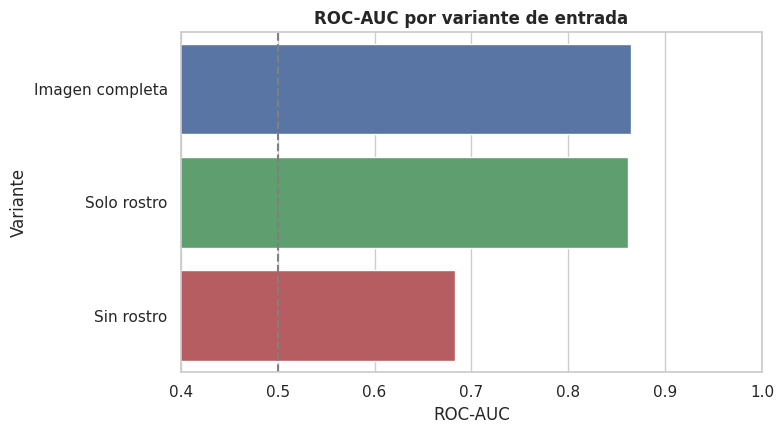

In [9]:
# ==============================================================================
# CELL 9: Tests 3 and 4 — embeddings and variant comparison
# ==============================================================================
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

print("GPU disponible:", bool(tf.config.list_physical_devices('GPU')))
backbone = EfficientNetV2B0(include_top=False, weights='imagenet',
                            pooling='avg', input_shape=(TAM, TAM, 3))
backbone.trainable = False

def embeddings(arr, nombre, lote=64):
    print(f"   Extrayendo: {nombre} ...")
    return np.vstack([
        backbone(preprocess_input(arr[i:i+lote].astype('float32')),
                 training=False).numpy()
        for i in range(0, len(arr), lote)])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
mk_clf = lambda: Pipeline([('scl', StandardScaler()),
                           ('lr', LogisticRegression(C=0.1, max_iter=3000,
                                                     random_state=SEED))])

E = {'Full image': completas, 'Face only': solo_rostro,
     'No face': sin_rostro}
filas_res = []
for nombre, arr in E.items():
    mask_v = det if nombre != 'Full image' else np.ones(len(y_img), bool)
    emb = embeddings(arr[mask_v], nombre)
    auc = cross_val_score(mk_clf(), emb, y_img[mask_v], cv=cv, scoring='roc_auc')
    acc = cross_val_score(mk_clf(), emb, y_img[mask_v], cv=cv, scoring='accuracy')
    filas_res.append({'Variant': nombre, 'n': int(mask_v.sum()),
                      'ROC-AUC': f"{auc.mean():.4f} ± {auc.std():.4f}",
                      'Accuracy (%)': f"{acc.mean()*100:.2f} ± {acc.std()*100:.2f}",
                      '_auc': float(auc.mean())})

df_res = pd.DataFrame(filas_res)
print("\n" + "=" * 88)
print(" TABLE — TESTS 3 AND 4 (frozen EfficientNetV2B0 + logistic, 10-fold CV)")
print("=" * 88)
print(df_res.drop(columns='_auc').to_string(index=False))
print("=" * 88)

AUC_COMPLETA = df_res.loc[df_res.Variant == 'Full image', '_auc'].iloc[0]
AUC_ROSTRO   = df_res.loc[df_res.Variant == 'Face only', '_auc'].iloc[0]
AUC_FONDO    = df_res.loc[df_res.Variant == 'No face', '_auc'].iloc[0]

plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_res, x='_auc', y='Variant',
            palette=['#4C72B0', '#55A868', '#C44E52'])
plt.axvline(0.5, ls='--', c='gray'); plt.xlim(0.4, 1.0)
plt.title("ROC-AUC by input variant", fontweight='bold'); plt.xlabel("ROC-AUC")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "pruebas34_resultados.png"), dpi=300)
plt.show()

---
## 6. Test 5 — Color ablation

Determines what fraction of the performance depends on color and lighting, and how much structure survives without them.

### 6.1 Transformations

**Replicated grayscale.** Removes chromatic information and keeps the luminance structure:

$$x^{\text{gray}}_{uvc} = Y_{uv} \quad \forall c \in \{1,2,3\}$$

**Per-image normalization.** Removes global color and brightness shifts while preserving local contrast. For each channel:

$$\tilde{x}_{uvc} = \operatorname{clip}\!\left(\frac{x_{uvc} - \mu_c}{\sigma_c},\ -\kappa,\ \kappa\right), \qquad x^{\text{norm}}_{uvc} = \frac{\tilde{x}_{uvc} + \kappa}{2\kappa}\cdot 255$$

with $\kappa = 2.5$. Clipping prevents outliers from compressing the rest of the dynamic range.

**Flat-color control.** Constant image with the mean color of the face, with no spatial structure at all:

$$x^{\text{flat}}_{uvc} = \bar{x}_c = \frac{1}{HW}\sum_{u',v'} x_{u'v'c} \quad \forall (u,v)$$

### 6.2 Why the flat control is decisive

Any discriminative ability on $x^{\text{flat}}$ **cannot come from facial anatomy**, because the image contains none. If this variant beats chance appreciably, the chromatic confounder is demonstrated unambiguously.


 TEST 5 — COLOR AND LIGHTING ABLATION ON THE FACE
 If the signal is facial morphology, it must survive removing the color.
 If it collapses toward the level of the metadata classifier (~0.74), what
 the model was learning was how the photo was taken, not the child's face.

 Generating variants...


[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]



 Extracting embeddings (may take a while on CPU)...
   Extrayendo: Original face ...
   Extrayendo: Grayscale ...
   Extrayendo: Color normalizado ...
   Extrayendo: Gris + normalizado ...
   Extrayendo: Mean color (control) ...

 TABLE — TEST 5: COLOR ABLATION (10-fold CV)
             Variant         ROC-AUC Accuracy (%)
      Original face 0.8619 ± 0.0231 77.76 ± 2.35
     Grayscale 0.8562 ± 0.0154 78.15 ± 2.22
    Color normalizado 0.8605 ± 0.0257 78.47 ± 3.04
   Gris + normalizado 0.8447 ± 0.0181 77.22 ± 2.13
Mean color (control) 0.6790 ± 0.0170 61.76 ± 1.80


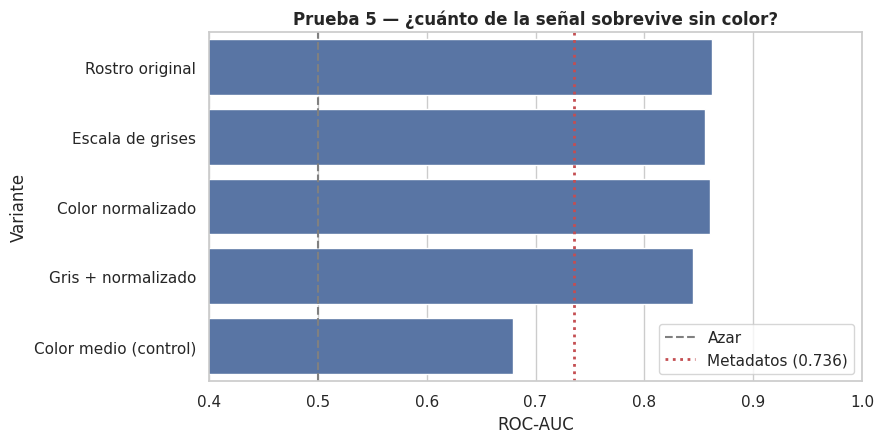


 TEST 5 VERDICT
------------------------------------------------------------------------------
  Original face         : 0.8619
  Gris + normalizado    : 0.8447
  Mean color (control) : 0.6790
  Metadata (ref.)      : 0.7357

  Drop when removing color: 0.0171

  A FLAT image of the mean color reaches AUC 0.6790.
  With no structure at all. Color is a severe and demonstrated confounder.
------------------------------------------------------------------------------


In [10]:
# ==============================================================================
# CELL 10: Test 5 — color ablation
# ==============================================================================
print("\n" + "=" * 78)
print(" TEST 5 — COLOR AND LIGHTING ABLATION ON THE FACE")
print("=" * 78)
print(" If the signal is facial morphology, it must survive removing the color.")
print(" If it collapses toward the level of the metadata classifier (~0.74), what")
print(" the model was learning was how the photo was taken, not the child's face.\n")

def a_gris(arr):
    """Luminance replicated in 3 channels: removes color, keeps structure."""
    g = (0.299*arr[..., 0] + 0.587*arr[..., 1] + 0.114*arr[..., 2])
    return np.repeat(g[..., None], 3, axis=2).astype(np.uint8)

def normalizar_por_imagen(arr):
    """Per-channel z-score within each image: removes global shifts
    in color and brightness, keeps local contrast and structure."""
    a = arr.astype(np.float32)
    for c in range(3):
        m, s = a[..., c].mean(), a[..., c].std() + 1e-6
        a[..., c] = np.clip((a[..., c] - m) / s, -2.5, 2.5)
    return (((a + 2.5) / 5.0) * 255).astype(np.uint8)

def color_solido(arr):
    """CONTROL: flat image with the mean color of the face. With no
    structure. If this already classifies, the artifact is confirmed."""
    return np.tile(arr.reshape(-1, 3).mean(axis=0).astype(np.uint8), (TAM, TAM, 1))

print(" Generating variants...")
rostro_gris    = np.array([a_gris(a) for a in solo_rostro], dtype=np.uint8)
rostro_norm    = np.array([normalizar_por_imagen(a) for a in solo_rostro], dtype=np.uint8)
rostro_gris_nm = np.array([normalizar_por_imagen(a_gris(a)) for a in solo_rostro],
                          dtype=np.uint8)
rostro_plano   = np.array([color_solido(a) for a in solo_rostro], dtype=np.uint8)

# View of the variants
fig, axes = plt.subplots(5, 4, figsize=(11, 13))
for c, i in enumerate(np.where(det)[0][:4]):
    for f, (arr, tit) in enumerate([
            (solo_rostro,    'Original face'),
            (rostro_gris,    'Grayscale'),
            (rostro_norm,    'Color normalizado'),
            (rostro_gris_nm, 'Gris + normalizado'),
            (rostro_plano,   'Mean color (control)')]):
        axes[f, c].imshow(arr[i]); axes[f, c].axis('off')
        if c == 0:
            axes[f, c].set_title(tit, loc='left', fontweight='bold', fontsize=10)
plt.suptitle("Test 5 — color ablation variants", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "prueba5_variantes.png"), dpi=300)
plt.show()

# --- Embedding extraction and evaluation ---
if 'backbone' not in dir():
    import tensorflow as tf
    from tensorflow.keras.applications import EfficientNetV2B0
    from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
    backbone = EfficientNetV2B0(include_top=False, weights='imagenet',
                                pooling='avg', input_shape=(TAM, TAM, 3))
    backbone.trainable = False

    def embeddings(arr, nombre, lote=64):
        print(f"   Extrayendo: {nombre} ...")
        return np.vstack([
            backbone(preprocess_input(arr[i:i+lote].astype('float32')),
                     training=False).numpy()
            for i in range(0, len(arr), lote)])

print("\n Extracting embeddings (may take a while on CPU)...")
VARIANTES = {
    'Original face'       : solo_rostro,
    'Grayscale'      : rostro_gris,
    'Color normalizado'     : rostro_norm,
    'Gris + normalizado'    : rostro_gris_nm,
    'Mean color (control)' : rostro_plano,
}

cv5 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
mk_clf = lambda: Pipeline([('scl', StandardScaler()),
                           ('lr', LogisticRegression(C=0.1, max_iter=3000,
                                                     random_state=SEED))])
filas5 = []
for nombre, arr in VARIANTES.items():
    emb = embeddings(arr, nombre)
    auc = cross_val_score(mk_clf(), emb[det], y_img[det], cv=cv5, scoring='roc_auc')
    acc = cross_val_score(mk_clf(), emb[det], y_img[det], cv=cv5, scoring='accuracy')
    filas5.append({'Variant': nombre, 'ROC-AUC': f"{auc.mean():.4f} ± {auc.std():.4f}",
                   'Accuracy (%)': f"{acc.mean()*100:.2f} ± {acc.std()*100:.2f}",
                   '_auc': auc.mean()})

df5 = pd.DataFrame(filas5)
print("\n" + "=" * 78)
print(" TABLE — TEST 5: COLOR ABLATION (10-fold CV)")
print("=" * 78)
print(df5.drop(columns='_auc').to_string(index=False))
print("=" * 78)
df5.drop(columns='_auc').to_csv(
    os.path.join(OUTPUTS_DIR, "tabla_prueba5_ablacion_color.csv"), index=False)

AUC_ORIG  = df5.loc[df5.Variant == 'Original face', '_auc'].iloc[0]
AUC_GRISN = df5.loc[df5.Variant == 'Gris + normalizado', '_auc'].iloc[0]
AUC_PLANO = df5.loc[df5.Variant == 'Mean color (control)', '_auc'].iloc[0]

plt.figure(figsize=(9, 4.6))
sns.barplot(data=df5, x='_auc', y='Variant', color='#4C72B0')
plt.axvline(0.5, ls='--', c='gray', label='Azar')
plt.axvline(AUC_META, ls=':', c='#C44E52', lw=2,
            label=f'Metadata ({AUC_META:.3f})')
plt.xlim(0.4, 1.0); plt.xlabel("ROC-AUC"); plt.legend()
plt.title("Test 5 — how much of the signal survives without color?", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "prueba5_resultados.png"), dpi=300)
plt.show()

print("\n TEST 5 VERDICT")
print("-" * 78)
print(f"  Original face         : {AUC_ORIG:.4f}")
print(f"  Gris + normalizado    : {AUC_GRISN:.4f}")
print(f"  Mean color (control) : {AUC_PLANO:.4f}")
print(f"  Metadata (ref.)      : {AUC_META:.4f}")
caida = AUC_ORIG - AUC_GRISN
print(f"\n  Drop when removing color: {caida:.4f}")

if AUC_PLANO > 0.65:
    P5 = "ARTIFACT CONFIRMED"
    print(f"\n  A FLAT image of the mean color reaches AUC {AUC_PLANO:.4f}.")
    print("  With no structure at all. Color is a severe and demonstrated confounder.")
elif AUC_GRISN < AUC_META + 0.03:
    P5 = "NO MORPHOLOGICAL SIGNAL"
    print("\n  Without color, performance falls to the level of the metadata classifier.")
    print("  There is no evidence of morphological signal independent of color.")
elif caida > 0.10:
    P5 = "MIXED SIGNAL"
    print("\n  Part of the signal survives, but color contributes a significant")
    print("  fraction. Train Phase 2 with color normalization.")
else:
    P5 = "MORPHOLOGICAL SIGNAL"
    print("\n  The signal survives without color: there is evidence of facial structure.")
print("-" * 78)

---
## 7. Deduplication and re-measurement

Test 1 detected near-duplicate pairs that cross splits. Since Tests 3 to 5 were validated on the pooled set, **all their values are inflated**. This section builds the clean cohort and measures again.

### 7.1 Connected components

The relation "near-duplicate of" is not transitive, but for deduplication it is convenient to treat it as such. The undirected graph $\mathcal{G} = (V, E)$ is built with

$$E = \left\{(a,b) : d_H\big(h^{(a)}, h^{(b)}\big) \leq \tau\right\}$$

Connected components are computed with *union-find* with path compression, of almost linear complexity $O(n \cdot \alpha(n))$, where $\alpha$ is the inverse Ackermann function. One representative is kept from each component $C_k$.

### 7.2 Groups with contradictory labels

A component is contradictory when

$$\left|\left\{y_i : i \in C_k\right\}\right| > 1$$

that is, it groups nearly identical images with opposite labels. There is no criterion to decide which one is correct, so the whole component is discarded.

### 7.3 Prior visual verification

**Part A of the cell shows flagged pairs side by side. They must be reviewed before continuing.** dHash may flag structurally similar faces of different subjects as duplicates. A sign of excessive chaining is the appearance of very large components: they do not correspond to copies of the same subject but to chains $A \approx B \approx C \approx \ldots$ If the pairs are not the same child, reduce $\tau$ in Cell 6 and repeat.

 PART A — VISUAL CHECK OF FLAGGED PAIRS
 dHash may flag structurally similar faces as duplicates.
 Review these pairs: if they are different children, lower the threshold and repeat.



[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]


>>> If they are NOT the same child, go back to cell 11 with THRESHOLD = 3 and repeat.
>>> If they ARE, continue: deduplication is necessary.

 PART B — GROUPING OF DUPLICATES
  Images              : 2801
  Unique groups       : 2793
  Groups with >1 image: 8
  Redundant images    : 8
  Largest group       : 2 images

  Groups with contradictory labels: 0
  Images affected                 : 0
  (nearly identical images labeled as both autism and typical:
   there is no way to know which label is correct, they are discarded)

 PART C — DEDUPLICATED COHORT
  Raw images                             : 2801
  (-) In groups with contradictory labels: 0
  (-) Redundant copies                  : 8
  = CLEAN COHORT                         : 2793

  Class distribution: {'typical': np.int64(1398), 'autism': np.int64(1395)}

 PART D — RE-MEASUREMENT ON CLEAN DATA
 All the previous AUCs were inflated by duplicates across folds.
 These are the usable numbers.

  effective n: 2793 | clases: {0: np.int6

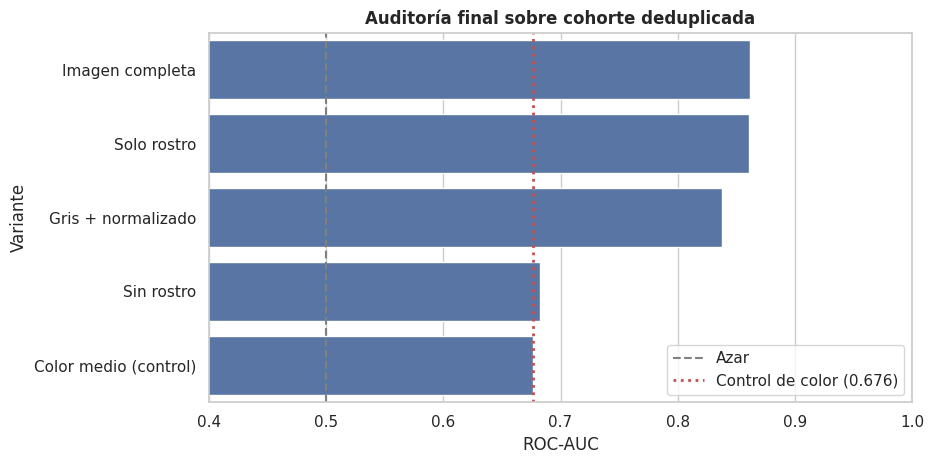


 SIGNAL DECOMPOSITION
------------------------------------------------------------------------------
  Total (full image)             : 0.8616
  Attributable to color only     : 0.6762  (flat control)
  Structure without color        : 0.8374
  Context outside the face       : 0.6826

  Gain of face over context     : +0.1785
  Loss when removing color              : +0.0237
------------------------------------------------------------------------------
 INTERPRETIVE WARNING: 'structure without color' includes hairstyle,
 framing, pose, sharpness and photographic style, not only facial morphology.
 Claiming morphology requires the geometric facial-landmark test.
------------------------------------------------------------------------------

{
  "n_crudo": 2801,
  "n_grupos_contradictorios": 0,
  "n_imagenes_contradictorias": 0,
  "n_redundantes": 8,
  "n_cohorte_limpia": 2793,
  "auc_imagen_completa": 0.8616,
  "auc_solo_rostro": 0.8611,
  "auc_gris_normalizado": 0.8374,
  "auc_sin_ros

In [11]:
# ==============================================================================
# CELL 11: Deduplication and re-measurement on clean data
# ==============================================================================
import numpy as np, os, json
from PIL import Image

# ==============================================================================
# PART A — Visual verification of the flagged pairs
# ==============================================================================
print("=" * 78)
print(" PART A — VISUAL CHECK OF FLAGGED PAIRS")
print("=" * 78)
print(" dHash may flag structurally similar faces as duplicates.")
print(" Review these pairs: if they are different children, lower the threshold and repeat.\n")

pares_cruce = [(i, j, d) for i, j, d in pares
               if base_h.split[i] != base_h.split[j]]
muestra = pares_cruce[:6] if pares_cruce else pares[:6]

if muestra:
    fig, axes = plt.subplots(2, len(muestra), figsize=(2.6 * len(muestra), 6))
    axes = np.atleast_2d(axes).reshape(2, -1)
    for c, (i, j, d) in enumerate(muestra):
        for f, k in enumerate([i, j]):
            try:
                axes[f, c].imshow(Image.open(base_h.ruta[k]).convert('RGB'))
            except Exception:
                pass
            axes[f, c].axis('off')
            axes[f, c].set_title(f"{base_h.split[k]}/{base_h.clase[k]}\n"
                                 f"{base_h.archivo[k]}", fontsize=8)
        axes[0, c].text(0.5, -0.08, f"Hamming = {d}", transform=axes[0, c].transAxes,
                        ha='center', fontsize=9, fontweight='bold')
    plt.suptitle("Pairs flagged as duplicates — is it the same child?",
                 fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUTS_DIR, "prueba1_pares_verificacion.png"), dpi=300)
    plt.show()

print(">>> If they are NOT the same child, go back to cell 11 with THRESHOLD = 3 and repeat.")
print(">>> If they ARE, continue: deduplication is necessary.\n")


# ==============================================================================
# PART B — Grouping into connected components (union-find)
# ==============================================================================
print("=" * 78)
print(" PART B — GROUPING OF DUPLICATES")
print("=" * 78)

padre = list(range(len(base_h)))

def buscar(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]
        x = padre[x]
    return x

def unir(a, b):
    ra, rb = buscar(a), buscar(b)
    if ra != rb:
        padre[rb] = ra

for i, j, _ in pares:
    unir(i, j)

grupo = np.array([buscar(k) for k in range(len(base_h))])
base_h = base_h.copy()
base_h['grupo'] = grupo

tam_grupo = base_h.groupby('grupo').size()
print(f"  Images              : {len(base_h)}")
print(f"  Unique groups       : {base_h.grupo.nunique()}")
print(f"  Groups with >1 image: {(tam_grupo > 1).sum()}")
print(f"  Redundant images    : {len(base_h) - base_h.grupo.nunique()}")
print(f"  Largest group       : {tam_grupo.max()} images")

# --- Groups with contradictory labels ---
clases_por_grupo = base_h.groupby('grupo')['clase'].nunique()
grupos_contradictorios = set(clases_por_grupo[clases_por_grupo > 1].index)
n_img_contra = int(base_h.grupo.isin(grupos_contradictorios).sum())
print(f"\n  Groups with contradictory labels: {len(grupos_contradictorios)}")
print(f"  Images affected                 : {n_img_contra}")
print("  (nearly identical images labeled as both autism and typical:")
print("   there is no way to know which label is correct, they are discarded)")


# ==============================================================================
# PART C — Building the clean cohort
# ==============================================================================
print("\n" + "=" * 78)
print(" PART C — DEDUPLICATED COHORT")
print("=" * 78)

valido = ~base_h.grupo.isin(grupos_contradictorios)
# One representative per group: the first of each connected component
representante = base_h[valido].drop_duplicates('grupo', keep='first')
idx_limpio = representante.index.to_numpy()

print(f"  Raw images                             : {len(base_h)}")
print(f"  (-) In groups with contradictory labels: {n_img_contra}")
print(f"  (-) Redundant copies                  : "
      f"{int(valido.sum()) - len(representante)}")
print(f"  = CLEAN COHORT                         : {len(representante)}")
print(f"\n  Class distribution: {dict(representante.clase.value_counts())}")

representante[['ruta','archivo','split','clase','grupo']].to_csv(
    os.path.join(OUTPUTS_DIR, "cohorte_imagenes_deduplicada.csv"), index=False)


# ==============================================================================
# PART D — Re-measuring the variants on the clean cohort
# ==============================================================================
print("\n" + "=" * 78)
print(" PART D — RE-MEASUREMENT ON CLEAN DATA")
print("=" * 78)
print(" All the previous AUCs were inflated by duplicates across folds.")
print(" These are the usable numbers.\n")

mask = np.zeros(len(base_h), dtype=bool)
mask[idx_limpio] = True

# Alignment guard: base_h comes from cell 11 and the image arrays from
# cell 8. If an image failed in one and not in the other, the indices
# would become misaligned and we would be masking the wrong rows.
n_arr = len(completas)
if len(base_h) != n_arr:
    raise RuntimeError(
        f"Misalignment: base_h has {len(base_h)} rows and the image arrays "
        f"{n_arr}. Run cells 8 and 11 again in sequence, without skipping any,"
        f"so that both traverse mf_ok in the same order.")

mask = mask & det                      # only where a face was detected
y_limpio = y_img[mask]
print(f"  effective n: {mask.sum()} | clases: {dict(pd.Series(y_limpio).value_counts())}")

VARIANTES_FINAL = {
    'Full image'       : completas,
    'Face only'           : solo_rostro,
    'Gris + normalizado'    : rostro_gris_nm,
    'No face'            : sin_rostro,
    'Mean color (control)' : rostro_plano,
}

cv_f = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
mk = lambda: Pipeline([('scl', StandardScaler()),
                       ('lr', LogisticRegression(C=0.1, max_iter=3000,
                                                 random_state=SEED))])
filas_f = []
for nombre, arr in VARIANTES_FINAL.items():
    emb = embeddings(arr[mask], nombre)
    auc = cross_val_score(mk(), emb, y_limpio, cv=cv_f, scoring='roc_auc')
    acc = cross_val_score(mk(), emb, y_limpio, cv=cv_f, scoring='accuracy')
    filas_f.append({'Variant': nombre,
                    'ROC-AUC': f"{auc.mean():.4f} ± {auc.std():.4f}",
                    'Accuracy (%)': f"{acc.mean()*100:.2f} ± {acc.std()*100:.2f}",
                    '_auc': float(auc.mean())})

df_f = pd.DataFrame(filas_f)
print("\n" + "=" * 78)
print(f" FINAL TABLE — AUDIT ON DEDUPLICATED COHORT (n={int(mask.sum())})")
print("=" * 78)
print(df_f.drop(columns='_auc').to_string(index=False))
print("=" * 78)
df_f.drop(columns='_auc').to_csv(
    os.path.join(OUTPUTS_DIR, "tabla_final_auditoria_limpia.csv"), index=False)

g = lambda n: df_f.loc[df_f.Variant == n, '_auc'].iloc[0]
A_COMP, A_ROST = g('Full image'), g('Face only')
A_GRIS, A_FOND, A_PLANO = g('Gris + normalizado'), g('No face'), g('Mean color (control)')

plt.figure(figsize=(9.5, 4.8))
sns.barplot(data=df_f, x='_auc', y='Variant', color='#4C72B0')
plt.axvline(0.5, ls='--', c='gray', label='Azar')
plt.axvline(A_PLANO, ls=':', c='#C44E52', lw=2,
            label=f'Control de color ({A_PLANO:.3f})')
plt.xlim(0.4, 1.0); plt.xlabel("ROC-AUC"); plt.legend(loc='lower right')
plt.title("Final audit on deduplicated cohort", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "auditoria_final_limpia.png"), dpi=300)
plt.show()

# --- Signal decomposition ---
print("\n SIGNAL DECOMPOSITION")
print("-" * 78)
print(f"  Total (full image)             : {A_COMP:.4f}")
print(f"  Attributable to color only     : {A_PLANO:.4f}  (flat control)")
print(f"  Structure without color        : {A_GRIS:.4f}")
print(f"  Context outside the face       : {A_FOND:.4f}")
print(f"\n  Gain of face over context     : {A_ROST - A_FOND:+.4f}")
print(f"  Loss when removing color              : {A_ROST - A_GRIS:+.4f}")
print("-" * 78)
print(" INTERPRETIVE WARNING: 'structure without color' includes hairstyle,")
print(" framing, pose, sharpness and photographic style, not only facial morphology.")
print(" Claiming morphology requires the geometric facial-landmark test.")
print("-" * 78)

veredicto_final = {
    'n_crudo': int(len(base_h)),
    'n_grupos_contradictorios': int(len(grupos_contradictorios)),
    'n_imagenes_contradictorias': n_img_contra,
    'n_redundantes': int(int(valido.sum()) - len(representante)),
    'n_cohorte_limpia': int(mask.sum()),
    'auc_imagen_completa': round(A_COMP, 4),
    'auc_solo_rostro': round(A_ROST, 4),
    'auc_gris_normalizado': round(A_GRIS, 4),
    'auc_sin_rostro': round(A_FOND, 4),
    'auc_color_medio_control': round(A_PLANO, 4),
    'ganancia_rostro_vs_contexto': round(A_ROST - A_FOND, 4),
}
with open(os.path.join(OUTPUTS_DIR, "veredicto_auditoria_final.json"), 'w') as f:
    json.dump(veredicto_final, f, indent=2, ensure_ascii=False)
print("\n" + json.dumps(veredicto_final, indent=2, ensure_ascii=False))

---
## 8. Test 6 — Alignment and morphology

Separates the contribution of **framing** from the contribution of **facial shape**.

### 8.1 Normalized facial landmarks

YuNet returns five points: right eye $\mathbf{o}_r$, left eye $\mathbf{o}_l$, nose tip $\mathbf{n}$, right mouth corner $\mathbf{b}_r$ and left mouth corner $\mathbf{b}_l$, normalized by the image dimensions:

$$\tilde{\mathbf{p}} = \left(\frac{p_x}{W},\ \frac{p_y}{H}\right) \in [0,1]^2$$

### 8.2 Dispersion ratio

For each of the ten coordinates:

$$\rho_k = \frac{\sigma_k^{\text{autism}}}{\sigma_k^{\text{typical}}}$$

Synthetic face generators produce aligned images, with facial landmarks at almost fixed positions. If one class were composed of generated faces, its dispersion would be substantially lower and $\rho_k \gg 1$. Values of $\rho$ close to 1 rule out that hypothesis.

### 8.3 Invariant geometric ratios

To measure shape independently of position, scale and rotation. With the interocular distance $d_{\text{io}} = \|\mathbf{o}_l - \mathbf{o}_r\|_2$ and the midpoints $\mathbf{m}_o = \tfrac{1}{2}(\mathbf{o}_r + \mathbf{o}_l)$, $\mathbf{m}_b = \tfrac{1}{2}(\mathbf{b}_r + \mathbf{b}_l)$:

$$
\begin{aligned}
r_1 &= \frac{\|\mathbf{b}_l - \mathbf{b}_r\|}{d_{\text{io}}} && \text{relative mouth width}\\[3pt]
r_2 &= \frac{\|\mathbf{n} - \mathbf{m}_o\|}{d_{\text{io}}} && \text{nasal projection}\\[3pt]
r_3 &= \frac{\|\mathbf{m}_b - \mathbf{n}\|}{d_{\text{io}}} && \text{nose-mouth distance}\\[3pt]
r_4 &= \frac{\|\mathbf{m}_b - \mathbf{m}_o\|}{d_{\text{io}}} && \text{relative facial height}\\[3pt]
r_5 &= \left|\arctan\frac{(\mathbf{o}_l - \mathbf{o}_r)_y}{(\mathbf{o}_l - \mathbf{o}_r)_x}\right| && \text{tilt of the eye line}\\[3pt]
r_6 &= \frac{\|\mathbf{n} - \mathbf{m}_b\|}{\|\mathbf{n} - \mathbf{m}_o\|} = \frac{r_3}{r_2} && \text{middle/lower third proportion}
\end{aligned}
$$

Ratios $r_1$ to $r_4$ and $r_6$ are invariant to translation, scale and rotation; $r_5$ measures precisely the rotation and is included as a framing control. The construction follows the approach of Aldridge et al. (2011), which uses normalized inter-point distances.

> **Two limitations that must be declared.** First: $r_6 = r_3/r_2$ is linearly dependent on the previous ones and adds no new information; it is kept for clinical interpretability. Second, and more relevant: **five facial landmarks are a very poor basis for characterizing morphology.** The reference literature uses dense three-dimensional meshes with dozens of points. The result must be stated as *"no morphological signal is detected with five facial landmarks"*, never as *"no morphological signal exists"*.

 TEST 6 — FACIAL ALIGNMENT REGULARITY

Extracting facial landmarks...
   0/2793
   400/2793
   800/2793
   1200/2793
   1600/2793
   2000/2793
   2400/2793

Points extracted: 2793 de 2793

 DISPERSION OF FACIAL LANDMARKS BY CLASS
 Standard deviation of each normalized coordinate. Much lower values
 in one class indicate aligned faces (generated or preprocessed).

     Punto  std autism  std typical  ratio aut/typ
 ojo_der_x      0.0858       0.0719           1.19
 ojo_der_y      0.0805       0.0650           1.24
 ojo_izq_x      0.0845       0.0731           1.16
 ojo_izq_y      0.0844       0.0668           1.26
   nariz_x      0.1152       0.0996           1.16
   nariz_y      0.0771       0.0668           1.15
boca_der_x      0.0900       0.0727           1.24
boca_der_y      0.0595       0.0586           1.02
boca_izq_x      0.0924       0.0782           1.18
boca_izq_y      0.0614       0.0589           1.04

 Mean dispersion ratio (autism / typical): 1.16
 >> Comparable dispersio

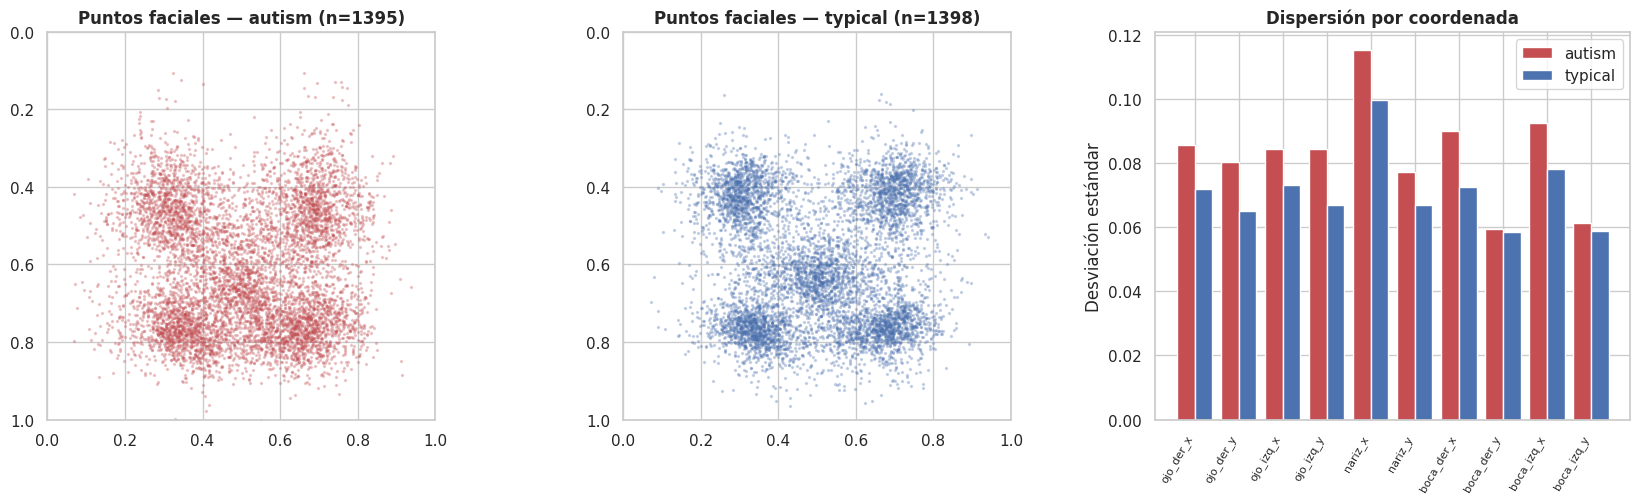


 RESULTS
  Landmark positions (alignment)        : AUC 0.7116 ± 0.0233
  Geometric ratios (morphology)         : AUC 0.5993 ± 0.0316
  Reference — flat-color control       : AUC 0.6762
  Reference — normalized gray face      : AUC 0.8374

 VERDICT
------------------------------------------------------------------------------
 The geometric ratios stay at 0.5993, close to chance. With 5
 facial landmarks no morphological signal is detected. The 0.84 of the visual
 model comes from texture, framing or photographic style.
------------------------------------------------------------------------------

{
  "n_con_landmarks": 2793,
  "razon_media_dispersion_aut_typ": 1.164,
  "auc_posiciones_alineacion": 0.7116,
  "auc_razones_geometricas": 0.5993,
  "auc_control_color": 0.6762,
  "auc_gris_normalizado": 0.8374,
  "veredicto": "NO MEASURABLE MORPHOLOGY"
}

>>> IMAGE BRANCH AUDIT CLOSED.


In [12]:
# ==============================================================================
# CELL 12: Test 6 — facial alignment and morphology
# ==============================================================================
import numpy as np, os, json
from PIL import Image

print("=" * 78)
print(" TEST 6 — FACIAL ALIGNMENT REGULARITY")
print("=" * 78)

if BACKEND != 'yunet':
    raise RuntimeError("This test needs YuNet (returns 5 facial landmarks). "
                       "Run cell 8 again with the yunet backend.")

# ------------------------------------------------------------------------------
# 13.1 — Extraction of the 5 facial landmarks
# ------------------------------------------------------------------------------
# YuNet returns per face: [x, y, w, h, right_eye(2), left_eye(2), nose(2),
#                           right_mouth(2), left_mouth(2), score]
print("\nExtracting facial landmarks...")
LM, ok_lm = [], []
sub = base_h[mask].reset_index(drop=True)
y_sub = y_img[mask]

for i, r in sub.iterrows():
    if i % 400 == 0:
        print(f"   {i}/{len(sub)}")
    try:
        img = np.asarray(Image.open(r['ruta']).convert('RGB'))
        h, w = img.shape[:2]
        _yunet.setInputSize((w, h))
        _, caras = _yunet.detect(np.ascontiguousarray(img[:, :, ::-1]))
        if caras is None or not len(caras):
            ok_lm.append(False); LM.append(np.zeros(10)); continue
        f = max(caras, key=lambda c: c[2] * c[3])
        pts = np.array(f[4:14], dtype=np.float32).reshape(5, 2)
        pts[:, 0] /= w; pts[:, 1] /= h          # normalized coordinates 0-1
        LM.append(pts.flatten()); ok_lm.append(True)
    except Exception:
        ok_lm.append(False); LM.append(np.zeros(10))

LM = np.array(LM); ok_lm = np.array(ok_lm)
print(f"\nPoints extracted: {ok_lm.sum()} de {len(sub)}")

L, yL = LM[ok_lm], y_sub[ok_lm]
NOMBRES = ['ojo_der_x','ojo_der_y','ojo_izq_x','ojo_izq_y','nariz_x','nariz_y',
           'boca_der_x','boca_der_y','boca_izq_x','boca_izq_y']

# ------------------------------------------------------------------------------
# 13.2 — Dispersion of the landmarks by class  (the central test)
# ------------------------------------------------------------------------------
print("\n" + "=" * 78)
print(" DISPERSION OF FACIAL LANDMARKS BY CLASS")
print("=" * 78)
print(" Standard deviation of each normalized coordinate. Much lower values")
print(" in one class indicate aligned faces (generated or preprocessed).\n")

filas = []
for k, nom in enumerate(NOMBRES):
    s_aut = L[yL == 1, k].std()
    s_typ = L[yL == 0, k].std()
    filas.append({'Punto': nom, 'std autism': round(float(s_aut), 4),
                  'std typical': round(float(s_typ), 4),
                  'ratio aut/typ': round(float(s_aut / (s_typ + 1e-9)), 2)})
df_disp = pd.DataFrame(filas)
print(df_disp.to_string(index=False))

razon_media = float(df_disp['ratio aut/typ'].mean())
print(f"\n Mean dispersion ratio (autism / typical): {razon_media:.2f}")
if razon_media > 1.8:
    print(" >> 'typical' is MUCH more aligned. Strong indication of")
    print("    generated or pre-aligned faces in that class.")
elif razon_media > 1.3:
    print(" >> 'typical' is more aligned. Moderate indication of different")
    print("    preprocessing between classes.")
else:
    print(" >> Comparable dispersion. No evidence of artificial alignment.")

# Visualization: cloud of facial landmarks by class
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, (cl, etq, col) in zip(axes[:2],
        [(1, 'autism', '#C44E52'), (0, 'typical', '#4C72B0')]):
    P = L[yL == cl].reshape(-1, 5, 2)
    for p in range(5):
        ax.scatter(P[:, p, 0], P[:, p, 1], s=2, alpha=0.25, color=col)
    ax.set_xlim(0, 1); ax.set_ylim(1, 0); ax.set_aspect('equal')
    ax.set_title(f"Facial landmarks — {etq} (n={len(P)})", fontweight='bold')

axes[2].bar(np.arange(len(NOMBRES)) - 0.2, df_disp['std autism'], 0.4,
            label='autism', color='#C44E52')
axes[2].bar(np.arange(len(NOMBRES)) + 0.2, df_disp['std typical'], 0.4,
            label='typical', color='#4C72B0')
axes[2].set_xticks(range(len(NOMBRES)))
axes[2].set_xticklabels(NOMBRES, rotation=60, ha='right', fontsize=8)
axes[2].set_ylabel("Standard deviation"); axes[2].legend()
axes[2].set_title("Dispersion per coordinate", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "prueba6_alineacion.png"), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 13.3 — Classify using ONLY the positions (not a single pixel of the face)
# ------------------------------------------------------------------------------
cv6 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
mk6 = lambda: Pipeline([('scl', StandardScaler()),
                        ('lr', LogisticRegression(C=1.0, max_iter=3000,
                                                  random_state=SEED))])
auc_pos = cross_val_score(mk6(), L, yL, cv=cv6, scoring='roc_auc')
AUC_POS = float(auc_pos.mean())

# ------------------------------------------------------------------------------
# 13.4 — Invariant geometric ratios  (the morphology test)
# ------------------------------------------------------------------------------
# Invariant to scale, translation and rotation: they describe the SHAPE of the face,
# not where it is or what color it is. This is what the facial phenotype
# literature on ASD uses (Aldridge et al., 2011).
def razones(v):
    p = v.reshape(5, 2)
    od, oi, na, bd, bi = p
    inter = np.linalg.norm(oi - od) + 1e-9
    medio_ojos  = (od + oi) / 2
    medio_boca  = (bd + bi) / 2
    return np.array([
        np.linalg.norm(bi - bd) / inter,                 # mouth width / interocular
        np.linalg.norm(na - medio_ojos) / inter,         # nose-eyes / interocular
        np.linalg.norm(medio_boca - na) / inter,         # mouth-nose / interocular
        np.linalg.norm(medio_boca - medio_ojos) / inter, # facial height / interocular
        abs(np.arctan2((oi - od)[1], (oi - od)[0])),     # tilt of the eye line
        np.linalg.norm(na - medio_boca) /
            (np.linalg.norm(na - medio_ojos) + 1e-9),    # middle/lower third proportion
    ])

G = np.array([razones(v) for v in L])
G = np.nan_to_num(G, nan=0.0, posinf=0.0, neginf=0.0)
auc_geo = cross_val_score(mk6(), G, yL, cv=cv6, scoring='roc_auc')
AUC_GEO = float(auc_geo.mean())

print("\n" + "=" * 78)
print(" RESULTS")
print("=" * 78)
print(f"  Landmark positions (alignment)        : AUC {AUC_POS:.4f} ± {auc_pos.std():.4f}")
print(f"  Geometric ratios (morphology)         : AUC {AUC_GEO:.4f} ± {auc_geo.std():.4f}")
print(f"  Reference — flat-color control       : AUC {A_PLANO:.4f}")
print(f"  Reference — normalized gray face      : AUC {A_GRIS:.4f}")
print("=" * 78)

print("\n VERDICT")
print("-" * 78)
if AUC_POS > 0.75:
    P6 = "ALINEACION ARTIFICIAL"
    print(f" The POSITIONS alone classify at {AUC_POS:.4f}, without looking at a pixel of")
    print(" the face. The classes have systematically different framing and alignment.")
    print(" It is an artifact of the origin of the images, not morphology.")
elif AUC_GEO > 0.65:
    P6 = "MORFOLOGIA PLAUSIBLE"
    print(f" The pure geometric ratios reach {AUC_GEO:.4f}. There is evidence of")
    print(" facial shape differences independent of color, texture and framing.")
else:
    P6 = "NO MEASURABLE MORPHOLOGY"
    print(f" The geometric ratios stay at {AUC_GEO:.4f}, close to chance. With 5")
    print(" facial landmarks no morphological signal is detected. The 0.84 of the visual")
    print(" model comes from texture, framing or photographic style.")
print("-" * 78)

veredicto6 = {
    'n_con_landmarks': int(ok_lm.sum()),
    'razon_media_dispersion_aut_typ': round(razon_media, 3),
    'auc_posiciones_alineacion': round(AUC_POS, 4),
    'auc_razones_geometricas': round(AUC_GEO, 4),
    'auc_control_color': round(float(A_PLANO), 4),
    'auc_gris_normalizado': round(float(A_GRIS), 4),
    'veredicto': P6,
}
with open(os.path.join(OUTPUTS_DIR, "veredicto_prueba6_alineacion.json"), 'w') as f:
    json.dump(veredicto6, f, indent=2, ensure_ascii=False)
df_disp.to_csv(os.path.join(OUTPUTS_DIR, "tabla_prueba6_dispersion.csv"), index=False)
print("\n" + json.dumps(veredicto6, indent=2, ensure_ascii=False))
print("\n>>> IMAGE BRANCH AUDIT CLOSED.")

---
## 9. Signal decomposition and closing

With all variants evaluated under an identical protocol, the observed performance is decomposed. Two contrasts are defined:

$$\Delta_{\text{face}} = A_{\text{face}} - A_{\text{background}}, \qquad \Delta_{\text{color}} = A_{\text{face}} - A_{\text{gray}}$$

> **Methodological warning.** These quantities **do not constitute an additive decomposition**. The variants share information: the mean color is contained in the full image, and the framing conditions both the face and the context. They must be read as lower bounds on the contribution of each factor, not as summands of a variance partition.

### 9.1 Connection with late fusion

The branch contributes to fusion through likelihood ratios:

$$LR^+ = \frac{Se}{1 - Sp}, \qquad LR^- = \frac{1 - Se}{Sp}$$

which are chained with the questionnaire branch under conditional independence:

$$\text{odds}_{\text{post}} = \frac{\pi}{1-\pi} \times LR_{\text{Q-CHAT}} \times LR_{\text{image}}, \qquad p_{\text{post}} = \frac{\text{odds}_{\text{post}}}{1 + \text{odds}_{\text{post}}}$$

**Mandatory sensitivity analysis.** If the audit shows that performance rests on capture artifacts that cannot be reproduced outside the dataset, the measured $LR$ overestimates the real contribution. The posterior probability must be reported over the range

$$LR_{\text{image}} \in \left[1.0,\ LR_{\text{measured}}\right]$$

where $LR = 1$ represents the scenario in which the branch adds no information and fusion reduces to the questionnaire.

 CONSOLIDATED VERDICT — IMAGE BRANCH AUDIT
 Test 1 — Duplicates across splits       : FALLA
 Test 2 — Classifier without image       : AUC 0.7357
 Test 3 — No face (context)              : AUC 0.6826
 Test 4 — Face only                      : AUC 0.8611
 Test 5 — Flat-color control             : AUC 0.6762
            Gris + normalizado           : AUC 0.8374
 Test 6 — Positions (framing)            : AUC 0.7116
            Geometric ratios (shape)     : AUC 0.5993
            Dispersion ratio             : 1.16

 TABLE — SIGNAL DECOMPOSITION
            Variant               What it contains  ROC-AUC
     Full image                       Todo   0.8616
         Face only Face with color and texture   0.8611
  Gris + normalizado          Texture without color   0.8374
Landmark positions      Framing and alignment   0.7116
          No face        Peripheral context   0.6826
   Flat mean color        Cromaticidad global   0.6762
 Geometric ratios               Facial shape   0.5993

 Del

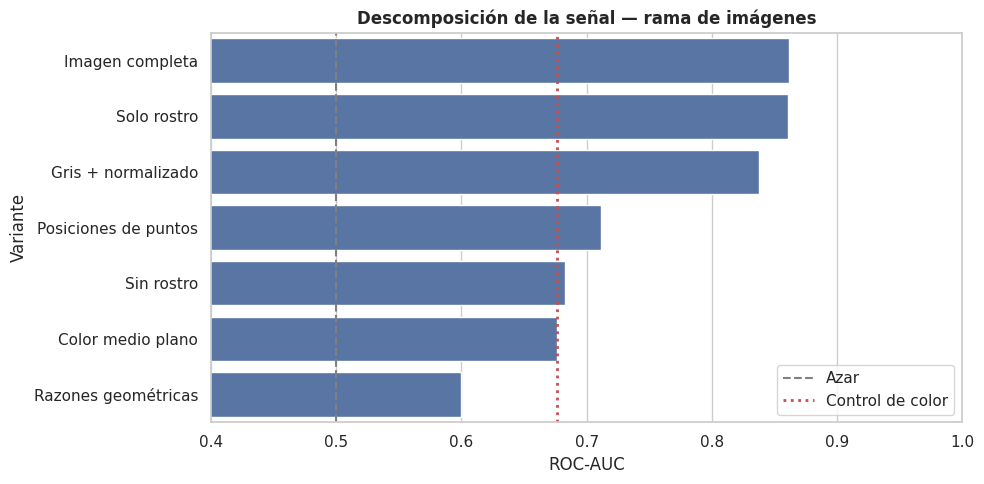


>>> IMAGE BRANCH AUDIT CLOSED.


In [13]:
# ==============================================================================
# CELL 13: Consolidated audit verdict
# ==============================================================================
print("=" * 84)
print(" CONSOLIDATED VERDICT — IMAGE BRANCH AUDIT")
print("=" * 84)
print(f" Test 1 — Duplicates across splits       : {P1}")
print(f" Test 2 — Classifier without image       : AUC {AUC_META:.4f}")
print(f" Test 3 — No face (context)              : AUC {A_FOND:.4f}")
print(f" Test 4 — Face only                      : AUC {A_ROST:.4f}")
print(f" Test 5 — Flat-color control             : AUC {A_PLANO:.4f}")
print(f"            Gris + normalizado           : AUC {A_GRIS:.4f}")
print(f" Test 6 — Positions (framing)            : AUC {AUC_POS:.4f}")
print(f"            Geometric ratios (shape)     : AUC {AUC_GEO:.4f}")
print(f"            Dispersion ratio             : {razon_media:.2f}")
print("=" * 84)

tabla_final = pd.DataFrame([
    {'Variant': 'Full image',      'What it contains': 'Todo',                      'ROC-AUC': round(A_COMP, 4)},
    {'Variant': 'Face only',          'What it contains': 'Face with color and texture','ROC-AUC': round(A_ROST, 4)},
    {'Variant': 'Gris + normalizado',   'What it contains': 'Texture without color',         'ROC-AUC': round(A_GRIS, 4)},
    {'Variant': 'Landmark positions', 'What it contains': 'Framing and alignment',     'ROC-AUC': round(AUC_POS, 4)},
    {'Variant': 'No face',           'What it contains': 'Peripheral context',       'ROC-AUC': round(A_FOND, 4)},
    {'Variant': 'Flat mean color',    'What it contains': 'Cromaticidad global',       'ROC-AUC': round(A_PLANO, 4)},
    {'Variant': 'Geometric ratios',  'What it contains': 'Facial shape',              'ROC-AUC': round(AUC_GEO, 4)},
]).sort_values('ROC-AUC', ascending=False)

print("\n TABLE — SIGNAL DECOMPOSITION")
print(tabla_final.to_string(index=False))
tabla_final.to_csv(os.path.join(OUTPUTS_DIR, "tabla_descomposicion_senal.csv"),
                   index=False)

print(f"\n Delta face vs context : {A_ROST - A_FOND:+.4f}")
print(f" Delta by color          : {A_ROST - A_GRIS:+.4f}")
print("\n REMINDER: these quantities are NOT an additive decomposition.")
print(" The variants share information; they are lower bounds per factor.")

plt.figure(figsize=(10, 5))
sns.barplot(data=tabla_final, x='ROC-AUC', y='Variant', color='#4C72B0')
plt.axvline(0.5, ls='--', c='gray', label='Azar')
plt.axvline(A_PLANO, ls=':', c='#C44E52', lw=2, label='Control de color')
plt.xlim(0.4, 1.0); plt.legend(loc='lower right')
plt.title("Signal decomposition — image branch", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "descomposicion_senal.png"), dpi=300)
plt.show()

with open(os.path.join(OUTPUTS_DIR, "veredicto_auditoria_consolidado.json"), 'w') as f:
    json.dump({'prueba1': P1, 'auc_metadatos': round(float(AUC_META), 4),
               'auc_imagen_completa': round(float(A_COMP), 4),
               'auc_solo_rostro': round(float(A_ROST), 4),
               'auc_gris_normalizado': round(float(A_GRIS), 4),
               'auc_sin_rostro': round(float(A_FOND), 4),
               'auc_color_plano': round(float(A_PLANO), 4),
               'auc_posiciones': round(float(AUC_POS), 4),
               'auc_geometria': round(float(AUC_GEO), 4),
               'razon_dispersion': round(float(razon_media), 3),
               'n_cohorte_limpia': int(mask.sum())},
              f, indent=2, ensure_ascii=False)

print("\n>>> IMAGE BRANCH AUDIT CLOSED.")